# 01 · Fire activity in Sumatra & Kalimantan, 2012–2025

What the forecast target looks like before any modelling.

**Data:** NASA FIRMS VIIRS S-NPP 375 m active-fire detections (nominal/high confidence, vegetation fires only), counted per 0.1° cell (~11 km) and per *local solar* day. A cell-day is a **fire cell-day** if it has at least one detection. Build the cubes first with `uv run titikapi build-static` and `uv run titikapi build-fire`.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from titikapi import viz
from titikapi.config import CUBE_DIR, ROOT
from titikapi.data.static import load_provinces
from titikapi.grid import Grid

viz.use_style()
FIG = ROOT / 'docs' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

grid = Grid()
fire = xr.open_zarr(CUBE_DIR / 'fire.zarr', consolidated=False)
static = xr.open_zarr(CUBE_DIR / 'static.zarr', consolidated=False)
mask = static['mask'].values
pid = static['province_id'].values[mask]
time = pd.DatetimeIndex(fire['time'].values)

# (days x land cells) boolean matrix, loaded a year at a time to keep memory low
cells = np.zeros((len(time), mask.sum()), dtype=bool)
for i in range(0, len(time), 366):
    cells[i:i + 366] = fire['fire_count'].isel(time=slice(i, i + 366)).values[:, mask] > 0

island = np.where(pid <= 10, 'Sumatra', 'Kalimantan')  # province ids 1-10 Sumatra, 11-15 Kalimantan
print(f'{len(time):,} days x {mask.sum():,} land cells; {cells.mean():.2%} of cell-days have fire')

5,095 days x 9,275 land cells; 1.36% of cell-days have fire


## How much burns, and when?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


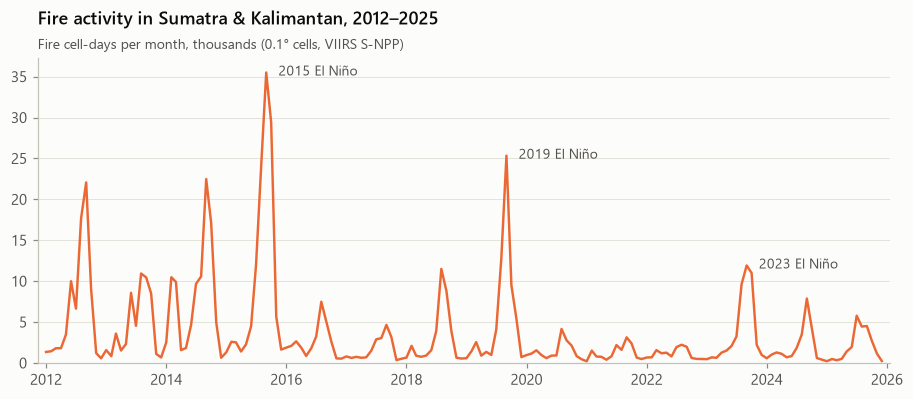

In [2]:
monthly = pd.Series(cells.sum(1), index=time).resample('MS').sum()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.index, monthly.values / 1000, color=viz.ORANGE, lw=1.6)
viz.titles(ax, 'Fire activity in Sumatra & Kalimantan, 2012–2025',
           'Fire cell-days per month, thousands (0.1° cells, VIIRS S-NPP)')
ax.set_ylim(0, None)
ax.margins(x=0.01)
for year in (2015, 2019, 2023):
    peak = monthly.loc[str(year)].idxmax()
    ax.annotate(f'{year} El Niño', (peak, monthly[peak] / 1000), xytext=(8, -2),
                textcoords='offset points', color=viz.INK_2, fontsize=9)
fig.savefig(FIG / 'eda_fire_timeline.png')
plt.show()

Activity is dominated by a few bad seasons. 2015 was the worst on record. 2019 and 2023, both El Niño years, are the next biggest peaks after 2014. The quiet years of 2020–2022 were La Niña years with wet dry seasons, and they also follow the post-2015 peat restoration and fire-prevention push. That makes the data **non-stationary**: a model trained on 2012–2020 has seen many more fire-heavy years than it will face in testing. This is one reason the test period (2023–2026) contains both an El Niño year and quiet years.

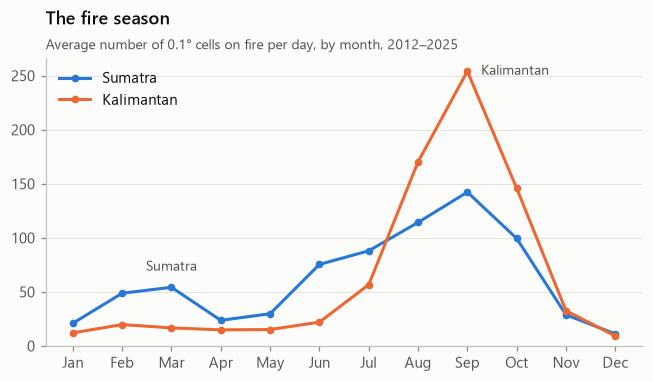

In [3]:
doy_month = time.month
fig, ax = plt.subplots(figsize=(7, 3.4))
for k, (name, color) in enumerate([('Sumatra', viz.SERIES[0]), ('Kalimantan', viz.SERIES[1])]):
    per_day = cells[:, island == name].sum(1)
    clim = pd.Series(per_day).groupby(doy_month).mean()
    ax.plot(clim.index, clim.values, color=color, marker='o', ms=4, label=name)
    at = 9 if name == 'Kalimantan' else 3  # label each line at its own distinctive point
    ax.annotate(name, (at, clim[at]), xytext=(9, 0) if at == 9 else (0, 9),
                textcoords='offset points', ha='left' if at == 9 else 'center',
                va='center' if at == 9 else 'bottom', color=viz.INK_2, fontsize=9)
ax.set_xticks(range(1, 13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
viz.titles(ax, 'The fire season', 'Average number of 0.1° cells on fire per day, by month, 2012–2025')
ax.legend(loc='upper left')
ax.set_ylim(0, None)
fig.savefig(FIG / 'eda_seasonality.png')
plt.show()

Both islands peak in **September**, at the end of the dry season. Sumatra also has a second, smaller season in **February–March**: Riau's short dry spell, when the big 2014 fires happened. Overall the two islands are almost evenly split (49% Sumatra, 51% Kalimantan).

## Where does it burn?

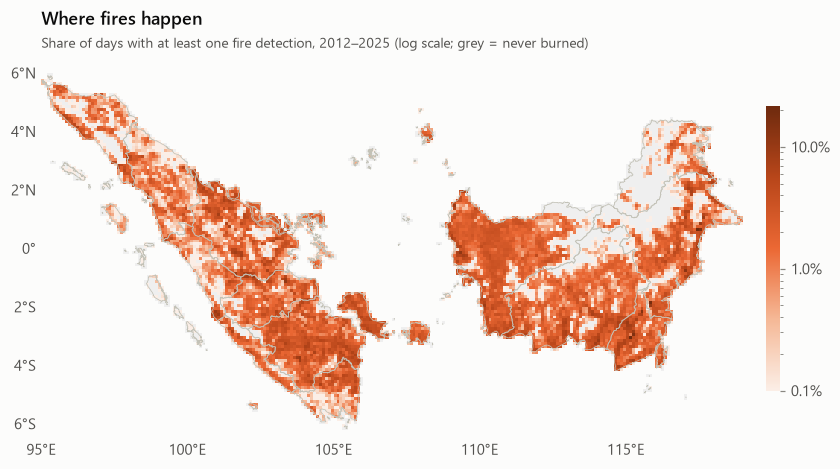

83% of land cells burned at least once


In [4]:
freq = np.full(grid.shape, np.nan)
freq[mask] = cells.mean(0)
provinces = load_provinces()

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.grid(False)
shown = np.ma.masked_invalid(np.where(freq > 0, freq, np.nan))
im = ax.imshow(shown, extent=viz.map_extent(grid), cmap=viz.FIRE_CMAP,
               norm=LogNorm(vmin=1e-3, vmax=np.nanmax(freq)), interpolation='nearest')
never = np.ma.masked_where(~(mask & (freq == 0)), np.ones(grid.shape))
ax.imshow(never, extent=viz.map_extent(grid), cmap='Greys', vmin=0, vmax=8, interpolation='nearest')
provinces.boundary.plot(ax=ax, color=viz.AXIS, linewidth=0.5)
ax.set_xlim(95, 119.5); ax.set_ylim(-6.5, 6.5)
ax.set_aspect('equal')
viz.degree_ticks(ax)
viz.titles(ax, 'Where fires happen',
           'Share of days with at least one fire detection, 2012–2025 (log scale; grey = never burned)')
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01)
cb.outline.set_visible(False)
cb.ax.tick_params(color=viz.MUTED, labelcolor=viz.INK_2)
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1%}'))
fig.savefig(FIG / 'eda_fire_map.png')
plt.show()
print(f'{(freq[mask] > 0).mean():.0%} of land cells burned at least once')

Fire is widespread: most land cells burned at least once in 14 years. The hot spots are the peatland belts of **eastern Sumatra** (Riau, Jambi, South Sumatra) and **southern Kalimantan** (Central, South and West Kalimantan), where drained peat burns for weeks. Mountains (the Barisan range in western Sumatra, central Borneo) rarely burn.

## Fire persists. So what should a forecast be judged on?

Fire today                          0.3178
Fire in past 2 weeks,\nnot today    0.0656
No fire in past 2 weeks             0.0046
New ignitions = 31.1% of all fire cell-days


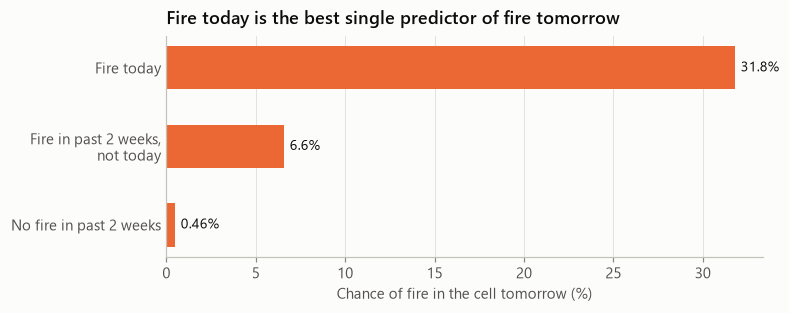

In [5]:
cs = np.cumsum(cells, axis=0, dtype=np.int16)
win = cs.copy(); win[14:] -= cs[:-14]          # fire cell-days in [t-13, t]
recent = win > 0
del cs, win
today, rec, tomorrow = cells[14:-1], recent[14:-1], cells[15:]
groups = {
    'Fire today': today,
    'Fire in past 2 weeks,\nnot today': rec & ~today,
    'No fire in past 2 weeks': ~rec,
}
rates = pd.Series({k: tomorrow[g].mean() for k, g in groups.items()})
new = tomorrow & ~rec
print(rates.round(4).to_string())
print(f'New ignitions = {new.sum() / tomorrow.sum():.1%} of all fire cell-days')

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
y = np.arange(len(rates))[::-1]
ax.barh(y, rates.values * 100, color=viz.ORANGE, height=0.55)
ax.set_yticks(y, rates.index)
for yi, v in zip(y, rates.values):
    ax.annotate(f'{v:.1%}' if v >= 0.01 else f'{v:.2%}', (v * 100, yi), xytext=(4, 0),
                textcoords='offset points', va='center', color=viz.INK, fontsize=9)
ax.set_xlabel('Chance of fire in the cell tomorrow (%)')
viz.titles(ax, 'Fire today is the best single predictor of fire tomorrow')
ax.tick_params(axis='y', length=0)
fig.savefig(FIG / 'eda_persistence.png')
plt.show()

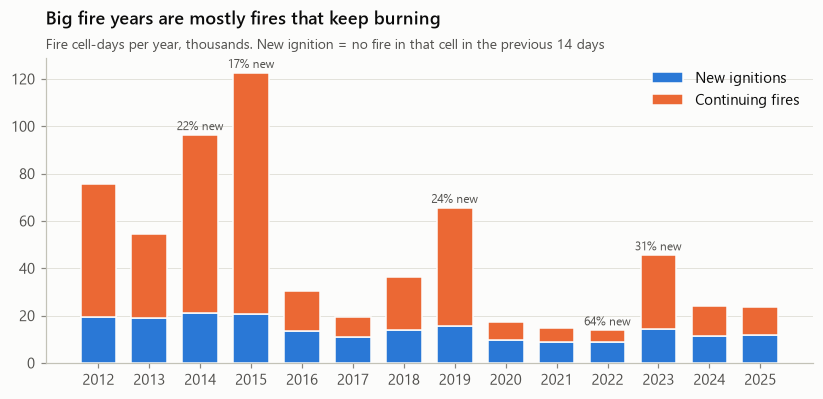

In [6]:
yearly = pd.DataFrame({'year': time[15:].year, 'new': new.sum(1),
                       'continuing': (tomorrow & rec).sum(1)}).groupby('year').sum()
yearly['new_share'] = yearly['new'] / (yearly['new'] + yearly['continuing'])

fig, ax = plt.subplots(figsize=(9, 3.6))
x = yearly.index.values
ax.bar(x, yearly['new'] / 1000, color=viz.SERIES[0], width=0.7, label='New ignitions',
       edgecolor=viz.SURFACE, linewidth=1)
ax.bar(x, yearly['continuing'] / 1000, bottom=yearly['new'] / 1000, color=viz.SERIES[1],
       width=0.7, label='Continuing fires', edgecolor=viz.SURFACE, linewidth=1)
labelled = (2014, 2015, 2019, 2022, 2023)  # a few contrasting years, not every bar
for xi, tot, share in zip(x, yearly['new'] + yearly['continuing'], yearly['new_share']):
    if xi in labelled:
        ax.annotate(f'{share:.0%} new', (xi, tot / 1000), xytext=(0, 3), textcoords='offset points',
                    ha='center', color=viz.INK_2, fontsize=8)
ax.set_xticks(x)
viz.titles(ax, 'Big fire years are mostly fires that keep burning',
           'Fire cell-days per year, thousands. New ignition = no fire in that cell in the previous 14 days')
ax.legend(loc='upper right')
fig.savefig(FIG / 'eda_new_vs_continuing.png')
plt.show()

## What this means for the model

1. **Persistence is a strong baseline.** A cell burning today has about a 32% chance of burning tomorrow, against 0.46% for a cell with no fire in two weeks, roughly 70× higher. Any model has to beat "tomorrow looks like today", and the evaluation reports it next to every result.
2. **New ignitions are where a forecast earns its keep.** They are 31% of fire cell-days overall, from 17% in 2015 to 64% in 2022. Persistence can't predict them by construction, so metrics are reported separately for this slice.
3. **Fire is rare and imbalanced.** About 1.4% of land cell-days have fire (3.3% in August–October). That calls for PR-AUC rather than ROC-AUC or accuracy, a loss that handles imbalance, and calibration checks.
4. **Fire activity changes from year to year** (El Niño, policy changes after 2015). Splits are by time, and results are broken down by El Niño and normal years.

Next: add weather and drought indicators (ERA5 → Fire Weather Index codes, rainfall memory), then the baselines.